# Recommender Systems - Mini Challenge HS26

In this mini challenge we will explore a MovieLens dataset and implement several recommender systems and evaluation methods. Subsequently we will optimize these methods and compare the results.

**Submission deadline:** Sunday of SW11 (Nov 29) at 18:00

## Guidelines for Implementation and Submission
- Code must be written in Python. Provide a `requirements.txt` with the pinned versions of all packages you used and state the Python version, so that your results are reproducible.
- You may respond in English or German.
- We develop numerous algorithms ourselves. Unless explicitly stated otherwise, only the following libraries may be used in Python: numpy, matplotlib, seaborn, pandas.
- Follow good coding practices and write modular, reusable code.
- The submitted solution must contain all code and the results. No code may be outsourced.
- All paths must be relative. Cloning your repository must be sufficient to run the notebook without any modifications.
- Fix all random seeds so that your results are reproducible.
- Only fully running code is graded. The notebook must run sequentially from start to end.
- During development, if computation time is too long for productive prototyping and debugging work, it is recommended to reduce the dataset to a fraction of its original size. However, final results must be calculated on the full dataset.
- All plots must be fully labeled (title, axes, labels, colorbar, etc.) so that the plot can be easily understood.
- Each plot must be accompanied by a brief discussion, which explains the plot and captures the key insights that become visible.
- Only fully labeled plots with an accompanying discussion will be assessed.
- Write concisely. Points will be deducted for unnecessarily long answers (denial of service will be punished).
- AI tools (e.g. ChatGPT, Claude, Copilot) may be used, but their use must be declared in the section *Declaration of AI usage* at the end of this notebook. You are responsible for all submitted code and text and must be able to explain every part of it at the MSP defense. Points will be deducted for text that was evidently written for the user of an AI tool rather than for the reader.
- The last commit in your fork of the repo before the submission deadline counts as the submission.
- If you would like to submit and have the mini-challenge assessed, please send a short email to the subject expert (moritz.kirschmann@fhnw.ch) within 2 days after submission.
- Please do not delete, duplicate, or move the existing cells. This leads to problems during the correction. However, you may add as many additional cells as you like.

## Exercises

### Exercise 1 - A deep exploration of the dataset (16 points)
We will work with a subset of the MovieLens dataset. This subset is located under ``Data/ml-latest-small``. Read the ``README.txt`` carefully.
Open the files.

a) Describe the available data.

b) Find and fix bad data (e.g. duplicates, missing values, etc.).

Generate lists of

c) - Top 20 movies by average rating

d) - Top 20 movies by number of ratings

e) What is the range of the ratings?

f) How many ratings were given per genre?

g) How sparse is the user-item matrix?

Plot the following:

h) How many users have rated how many movies

i) Which rating is given how often over time with a time resolution of month

j) Which rating is given how often per genre

k) The rating distributions of 10 random movies and of 3 movies that you have watched yourself

l) The popularity distribution of the movies (long tail): the number of ratings per movie as a function of the movie's popularity rank. Which share of all ratings do the 10% most-rated movies receive?

m) How many users give which average rating

n) How often a movie was rated as a function of average rating

o) A heatmap of the user-item matrix

p) A heatmap of the user-item matrix for the 100 most rated movies for the 50 users with most ratings


Integrity checks (raw data)
────────────────────────────────────────────────────────────
 ✔  duplicate rows (all files)               0   
 ✔  rating outside 0.5–5.0                   0   
 ✔  duplicate movieId                        0   
 ✘  duplicate title, different id            5   → see table
 ✔  duplicate (userId, movieId)              0   
 ✔  ratings → unknown movieId                0   
 ✔  tags → unknown movieId                   0   
 ✔  links → unknown movieId                  0   
 ✔  tags → user without ratings              0   
 ✘  movies without ratings                  18   no effect on RS
────────────────────────────────────────────────────────────
 ℹ  timespan: 1996-03-29 – 2018-09-24


movieId,imdbId,tmdbId,title
791,113610,nan,"Last Klezmer: Leopold Kozlowski, His Life and Music, The (1994)"
1107,102336,nan,Loser (1991)
2851,81454,nan,Saturn 3 (1980)
4051,56600,nan,Horrors of Spider Island (Ein Toter Hing im Netz) (1960)
26587,92337,nan,"Decalogue, The (Dekalog) (1989)"
32600,377059,nan,Eros (2004)
40697,105946,nan,Babylon 5
79299,874957,nan,"No. 1 Ladies' Detective Agency, The (2008)"


title,movieId,imdbId,tmdbId,n_ratings,decision
Confessions of a Dangerous Mind (2002),6003,290538,4912,15,merge: same tmdbId (4912)
Confessions of a Dangerous Mind (2002),144606,270288,4912,1,merge: same tmdbId (4912)
Emma (1996),838,116191,3573,30,keep: different versions
Emma (1996),26958,118308,12254,1,keep: different versions
Eros (2004),32600,377059,–,1,merge: same film on IMDb
Eros (2004),147002,343663,39850,1,merge: same film on IMDb
Saturn 3 (1980),2851,81454,–,4,merge: same film on IMDb
Saturn 3 (1980),168358,79285,19761,1,merge: same film on IMDb
War of the Worlds (2005),34048,407304,74,50,keep: different films
War of the Worlds (2005),64997,449040,34812,2,keep: different films


0


,before,after,removed
links,9742,9739,3
movies,9742,9739,3
ratings,100836,100835,1
tags,3683,3683,0


title,avg_rating,n_ratings
"Streetcar Named Desire, A (1951)",4.47,20
"Shawshank Redemption, The (1994)",4.43,317
Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.33,27
"Philadelphia Story, The (1940)",4.31,29
Lawrence of Arabia (1962),4.30,45
In the Name of the Father (1993),4.30,25
Hoop Dreams (1994),4.29,29
"Godfather, The (1972)",4.29,192
Harold and Maude (1971),4.29,26
Logan (2017),4.28,25


title,n_ratings,avg_rating
Forrest Gump (1994),329,4.16
"Shawshank Redemption, The (1994)",317,4.43
Pulp Fiction (1994),307,4.20
"Silence of the Lambs, The (1991)",279,4.16
"Matrix, The (1999)",278,4.19
Star Wars: Episode IV - A New Hope (1977),251,4.23
Jurassic Park (1993),238,3.75
Braveheart (1995),237,4.03
Terminator 2: Judgment Day (1991),224,3.97
Schindler's List (1993),220,4.22


[np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]


genre,n_ratings,avg_rating
Drama,41927,3.66
Comedy,39052,3.38
Action,30635,3.45
Thriller,26451,3.49
Adventure,24162,3.51
Romance,18122,3.51
Sci-Fi,17243,3.46
Crime,16680,3.66
Fantasy,11834,3.49
Children,9208,3.41


Users: 610, Filme: 9721, Ratings: 100835
Density: 1.7005%, Sparsity: 98.2995%


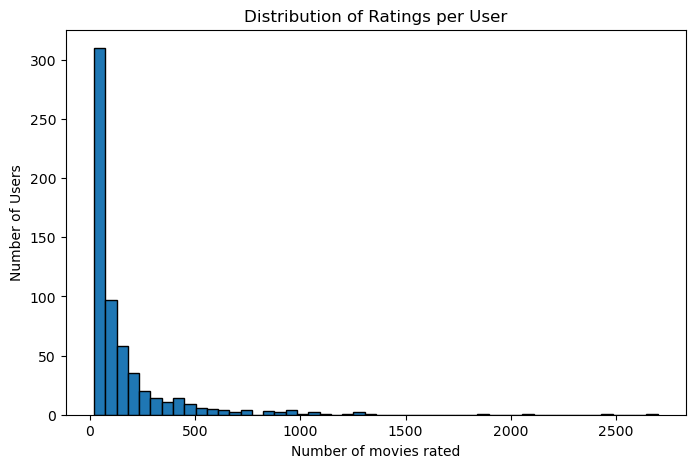

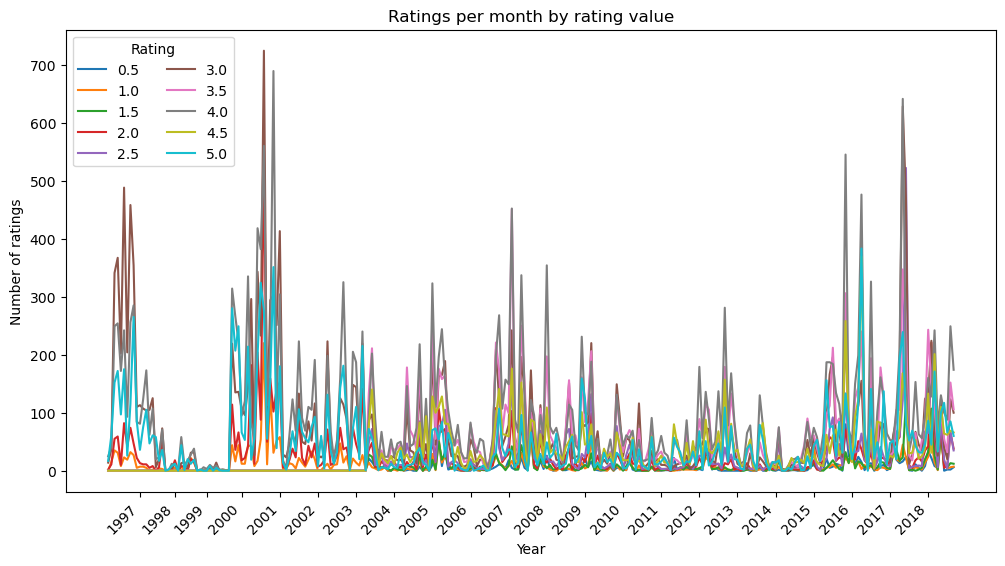

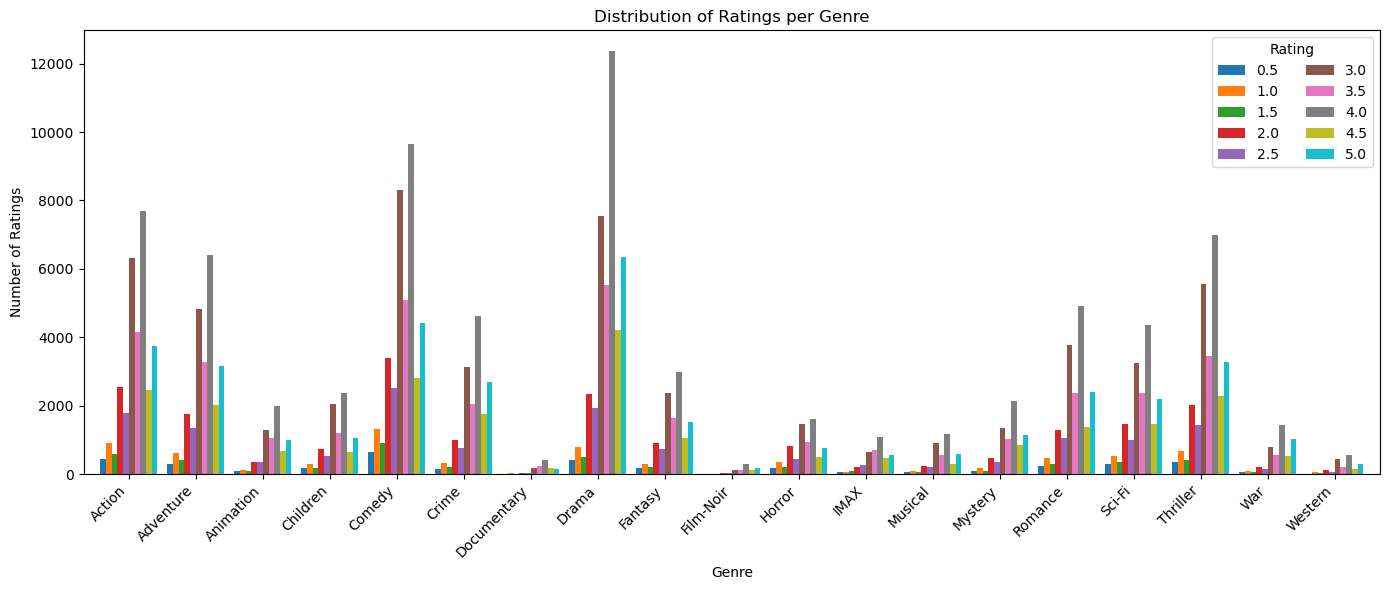

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display # only for styling
import matplotlib.pyplot as plt

links = pd.read_csv("Data/ml-latest-small/links.csv")
movies = pd.read_csv("Data/ml-latest-small/movies.csv")
ratings = pd.read_csv("Data/ml-latest-small/ratings.csv")
tags = pd.read_csv("Data/ml-latest-small/tags.csv")
da = [links, movies, ratings, tags]

"""  a)
everything is connected by a userid or movieid
"""
# ==========
# b
# ==========
def profile(dfs: dict) -> pd.DataFrame:
    """One row per column of every file: dtype, missing, unique values."""
    rows = []
    for name, d in dfs.items():
        for col in d.columns:
            rows.append({"file": name, "column": col, "dtype": str(d[col].dtype),
                         "missing": d[col].isna().sum(),
                         "missing %": d[col].isna().mean() * 100,
                         "unique": d[col].nunique()})
    return pd.DataFrame(rows).set_index(["file", "column"])

def check_report(title: str, checks: dict, width: int = 60):
    """Prints a test-style report: ✔ when the count is 0, ✘ otherwise."""
    print(f"\n{title}\n" + "─" * width)
    for label, (count, note) in checks.items():
        mark = "✔" if count == 0 else "✘"
        print(f" {mark}  {label:<36}{count:>6}   {note}")
    print("─" * width)

dfs = {"links": links, "movies": movies, "ratings": ratings, "tags": tags}
display(profile(dfs).style.format({"missing %": "{:.2f}"})
                    .bar(subset=["missing"], color="#f4a3a3"))

ts = pd.to_datetime(ratings["timestamp"], unit="s")
check_report("Integrity checks (raw data)", {
    "duplicate rows (all files)":    (sum(d.duplicated().sum() for d in dfs.values()), ""),
    "rating outside 0.5–5.0":        ((~ratings["rating"].between(0.5, 5)).sum(), ""),
    "duplicate movieId":             (movies["movieId"].duplicated().sum(), ""),
    "duplicate title, different id": (movies["title"].duplicated().sum(), "→ see table"),
    "duplicate (userId, movieId)":   (ratings.duplicated(["userId", "movieId"]).sum(), ""),
    "ratings → unknown movieId":     ((~ratings["movieId"].isin(movies["movieId"])).sum(), ""),
    "tags → unknown movieId":        ((~tags["movieId"].isin(movies["movieId"])).sum(), ""),
    "links → unknown movieId":       ((~links["movieId"].isin(movies["movieId"])).sum(), ""),
    "tags → user without ratings":   ((~tags["userId"].isin(ratings["userId"])).sum(), ""),
    "movies without ratings":        ((~movies["movieId"].isin(ratings["movieId"])).sum(), "no effect on RS"),
})
print(f" ℹ  timespan: {ts.min():%Y-%m-%d} – {ts.max():%Y-%m-%d}")


# NA rows in links
missing_links = links[links.isna().any(axis=1)].merge(movies[["movieId", "title"]], on="movieId")
display(missing_links.style.set_caption("Links without tmdbId").hide(axis="index")
                     .highlight_null(color="#f4a3a3"))  # 8 rows missing

# handling duplicate titles
movies["title"] = movies["title"].str.strip()   # 11 titles with leading/trailing whitespace

decisions = {
    "Confessions of a Dangerous Mind (2002)": "merge: same tmdbId (4912)",
    "Eros (2004)":                            "merge: same film on IMDb",
    "Saturn 3 (1980)":                        "merge: same film on IMDb",
    "Emma (1996)":                            "keep: different versions",
    "War of the Worlds (2005)":               "keep: different films",
}
n_per_movie = ratings.groupby("movieId").size().rename("n_ratings")
dups = (movies[movies["title"].duplicated(keep=False)]
        .merge(links, on="movieId").merge(n_per_movie, on="movieId", how="left")
        .assign(decision=lambda d: d["title"].map(decisions))
        .sort_values(["title", "n_ratings"], ascending=[True, False]))
display(dups[["title", "movieId", "imdbId", "tmdbId", "n_ratings", "decision"]]
        .style.set_caption("Duplicate titles and decision").hide(axis="index")
        .format({"tmdbId": "{:.0f}", "n_ratings": "{:.0f}"}, na_rep="–")
        .map(lambda v: "color:#b71c1c" if v.startswith("merge") else "color:#1b5e20",
             subset=["decision"]))

before = {name: len(d) for name, d in dfs.items()}

# Merging duplicates
id_map = {
    144606: 6003,    # Confessions of a Dangerous Mind
    147002: 32600,   # Eros (1 rating each, so either direction works)
    168358: 2851,    # Saturn 3 (2851 has 4 ratings)
}

# keep the tmdbId from the dropped row where the kept row has none
for old, new in id_map.items():
    old_tmdb = links.loc[links["movieId"] == old, "tmdbId"].iloc[0]
    mask = (links["movieId"] == new) & links["tmdbId"].isna()
    links.loc[mask, "tmdbId"] = old_tmdb

ratings["movieId"] = ratings["movieId"].replace(id_map)
tags["movieId"] = tags["movieId"].replace(id_map)
movies = movies[~movies["movieId"].isin(id_map.keys())]
links = links[~links["movieId"].isin(id_map.keys())]

ratings = (ratings.sort_values("timestamp")
                  .drop_duplicates(subset=["userId", "movieId"], keep="last")
                  .reset_index(drop=True))
assert ratings.duplicated(subset=["userId", "movieId"]).sum() == 0

# user may now have two ratings for the same movie
print(ratings.duplicated(subset=["userId", "movieId"]).sum())

# report
dfs = {"links": links, "movies": movies, "ratings": ratings, "tags": tags}
changes = pd.DataFrame({"before": before, "after": {n: len(d) for n, d in dfs.items()}})
changes["removed"] = changes["before"] - changes["after"]
display(changes.style.set_caption("Rows before / after cleaning")
               .map(lambda v: "font-weight:bold;color:#b71c1c" if v else "", subset=["removed"]))

# check_report("Integrity checks (after cleaning)", integrity_checks())


# =========
# c
# =========
m = 20 # minimal count of received ratings to be eligible
avg_rating = ratings.groupby("movieId")["rating"].agg(avg_rating="mean", n_ratings="count").reset_index()
top20 = (avg_rating[avg_rating["n_ratings"] >= 20]
         .sort_values("avg_rating", ascending=False)
         .head(20)
         .merge(movies[["movieId", "title"]], on="movieId"))

styler_c = (top20[["title", "avg_rating", "n_ratings"]]
    .style
    .set_caption(f"Top 20 movies after mean rating (min {m} ratings)")
    .format({"avg_rating": "{:.2f}"})
    .hide(axis="index"))
display(styler_c)

# =========
# d
# =========
most_rated = avg_rating.sort_values("n_ratings", ascending=False).head(20).merge(movies[["movieId", "title"]], on="movieId")

styler_d = (most_rated[["title", "n_ratings", "avg_rating"]]
    .style
    .set_caption("Top 20 movies by number of ratings")
    .format({"avg_rating": "{:.2f}"})
    .hide(axis="index"))
display(styler_d)


# =========
# e
# =========
print(sorted(ratings["rating"].unique()))

# =========
# f
# =========
movie_genres = (movies.assign(genre=movies["genres"].str.split("|"))
                .explode("genre")[["movieId", "genre"]])

genre_ratings = ratings.merge(movie_genres, on="movieId")
genre_counts = (genre_ratings.groupby("genre")["rating"]
                .agg(n_ratings="count", avg_rating="mean")
                .sort_values("n_ratings", ascending=False)
                .reset_index())

styler_e = (genre_counts[["genre", "n_ratings", "avg_rating"]]
    .style
    .set_caption("Counts and Average Rating per Genre")
    .format({"avg_rating": "{:.2f}"})
    .hide(axis="index"))
display(styler_e)

# ==========
# g
# ==========
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
n_ratings = len(ratings)

density = n_ratings / (n_users * n_movies)
sparsity = 1 - density

print(f"Users: {n_users}, Filme: {n_movies}, Ratings: {n_ratings}")
print(f"Density: {density:.4%}, Sparsity: {sparsity:.4%}")

# ============
# h
# ============

ratings_per_user = ratings.groupby("userId").size()
plt.figure(figsize=(8, 5))
plt.hist(ratings_per_user, bins=50, edgecolor="black")
plt.xlabel("Number of movies rated")
plt.ylabel("Number of Users")
plt.title("Distribution of Ratings per User")
plt.show()

# ============
# i
# ============
ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings["month"] = ratings["date"].dt.to_period("M")

counts = (ratings.groupby(["month", "rating"])
                .size()
                .unstack(fill_value=0))
counts.index = counts.index.to_timestamp()

ax = counts.reset_index(drop=True).plot(figsize=(12, 6))

jan = [i for i, d in enumerate(counts.index) if d.month == 1]   # Position jedes Januars
ax.set_xticks(jan)
ax.set_xticklabels([counts.index[i].year for i in jan], rotation=45, ha="right")

ax.set_xlabel("Year")
ax.set_ylabel("Number of ratings")
ax.set_title("Ratings per month by rating value")
ax.legend(title="Rating", ncol=2)
plt.show()

# ===========
# j
# ===========
genre_rating_counts = (genre_ratings.groupby(["genre", "rating"])
                                    .size()
                                    .unstack(fill_value=0))
genre_rating_counts = genre_rating_counts.drop(index="(no genres listed)", errors="ignore")
ax = genre_rating_counts.plot.bar(figsize=(14, 6), width=0.85)
ax.set_xlabel("Genre")
ax.set_ylabel("Number of Ratings")
ax.set_title("Distribution of Ratings per Genre")
ax.legend(title="Rating", ncol=2)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========
# k
# =========
def plot_rating_distributions(movie_ids, own_ids, ratings, movies, ncols=5):
    """Small multiples: share of each rating value per movie, overall distribution as reference."""
    levels = np.arange(0.5, 5.01, 0.5)
    overall = ratings["rating"].value_counts(normalize=True).reindex(levels, fill_value=0)
    titles = movies.set_index("movieId")["title"]

    nrows = int(np.ceil(len(movie_ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), sharex=True, sharey=True)
    for ax, mid in zip(axes.flat, movie_ids):
        r = ratings.loc[ratings["movieId"] == mid, "rating"]
        share = r.value_counts(normalize=True).reindex(levels, fill_value=0)
        own = mid in own_ids
        ax.bar(levels, share, width=0.4, color="tab:orange" if own else "tab:blue")
        ax.step(levels, overall, where="mid", color="grey", lw=1, label="all movies")
        ax.axvline(r.mean(), color="black", ls="--", lw=1)
        title = titles[mid] if len(titles[mid]) <= 34 else titles[mid][:26] + "… " + titles[mid][-6:]
        ax.set_title(f"{title}\nn={len(r)}, mean={r.mean():.2f}", fontsize=9,
                     fontweight="bold" if own else "normal")
        ax.set_xticks(np.arange(1, 6))
    for ax in axes[:, 0]:
        ax.set_ylabel("Share of ratings")
    for col in range(ncols):   # x label on the lowest visible plot of each column
        row = (len(movie_ids) - 1 - col) // ncols
        axes[row, col].set_xlabel("Rating")
        axes[row, col].tick_params(labelbottom=True)
    for ax in axes.flat[len(movie_ids):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle("Rating distributions: 10 random movies (blue) and 3 own picks (orange), dashed = mean",
                 fontweight="bold")
    fig.tight_layout()
    plt.show()

own_ids = [143355, 147372, 148172]   # Wonder Woman (2017), Doctor Who: Last Christmas (2014), The 5th Wave (2016)
n_per_movie = ratings.groupby("movieId").size()
pool = n_per_movie[(n_per_movie >= 10) & ~n_per_movie.index.isin(own_ids)].index   # >= 10 ratings, so the distribution is meaningful
rng = np.random.default_rng(42)
random_ids = list(rng.choice(pool, size=10, replace=False))

plot_rating_distributions(random_ids + own_ids, own_ids, ratings, movies)

# ==========
# l
# ==========
counts = (ratings.groupby("movieId").size()
                 .sort_values(ascending=False)
                 .reset_index(drop=True))
rank = counts.index + 1

# Long tail plot
plt.figure(figsize=(8, 5))
plt.plot(rank, counts.values)
plt.xlabel("Popularity rank of movie")
plt.ylabel("Number of ratings")
plt.title("Long tail of movie popularity")
plt.show()
# 10%
n_top = int(np.ceil(0.10 * len(counts)))
share_top10 = counts.iloc[:n_top].sum() / counts.sum()
print(f"Top 10% of movies ({n_top} of {len(counts)}) receive {share_top10:.1%} of all ratings")

# ==========
# m
# ==========
avg_user_rating = (ratings.groupby("userId")["rating"]
                   .agg(avg_rating="mean", n_ratings="count")
                   .reset_index())

plt.figure(figsize=(12, 6))
plt.hist(avg_user_rating["avg_rating"], bins=30, edgecolor="black")
plt.xlabel("avg User Rating")
plt.ylabel("Number of users")
plt.title("Distribution of average rating per user")
plt.show()

# =========
# n
# =========
plt.figure(figsize=(8, 5))
plt.scatter(avg_rating["avg_rating"], avg_rating["n_ratings"], s=8, alpha=0.4)
plt.yscale("log")
plt.xlabel("Average rating of movie")
plt.ylabel("Number of ratings (log scale)")
plt.title("Number of ratings vs. average rating per movie")
plt.show()

# ==========
# o
# ==========

user_item_matrix = ratings.pivot(index="userId", columns="movieId", values="rating")

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(user_item_matrix.values, aspect="auto", cmap="viridis", interpolation="nearest")
ax.set_xlabel("Movies (columns)")
ax.set_ylabel("Users (Rows)")
ax.set_title("User-Item Matrix")
fig.colorbar(im, label="Rating")
plt.show()


# ===========
# p
# ===========
top_users = ratings.groupby("userId").size().nlargest(50).index
top_movies = ratings.groupby("movieId").size().nlargest(100).index

sub = user_item_matrix.loc[top_users, top_movies]

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgray")          # missing ratings

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(np.ma.masked_invalid(sub.values), aspect="auto", cmap=cmap, interpolation="nearest")
ax.set_xlabel("Movies (100 most rated, most rated on the left)")
ax.set_ylabel("Users (50 most active, most active on top)")
ax.set_title("User-item matrix: top 50 users x top 100 movies")
fig.colorbar(im, label="Rating")
plt.show()


#### Discussion of Plots

not done yet

### Exercise 2 - Building baseline RS (8 points)
In this exercise we will build simple baseline RS that serve as reference points for all later models.

Build the following baseline RS to predict Top-N (default N=20):
In reference to the book *Collaborative Filtering Recommender Systems by Michael D. Ekstrand, John T. Riedl and Joseph A. Konstan* (p. 91ff) implement the baseline predictor $$ b_{u,i}= \mu +b_u +b_i $$ with the regularized user and item average offsets: $$ b_u = \frac{1}{|I_u| + \beta_u} \sum_{i \in I_u} (r_{u,i} - \mu) $$ and $$ b_i = \frac{1}{|U_i| + \beta_i} \sum_{u \in U_i} (r_{u,i} - b_u - \mu) . $$ 
Where:
- $\mu$ = Global mean value of all ratings
- $r_{u,i}$ = Rating from user u to item i
- $|I_u|$ = Number of items which user u has rated
- $|U_i|$ = Number of users which have rated item i
- $b_u$ = User-Offset
- $b_i$ = Item-Offset


1. Build a recommender system upon this baseline predictor. Set the default damping factors $\beta_u$ and $\beta_i$ both to 20.
2. Build a RS that recommends based on *random* recommendations.
3. Build a RS that recommends the most *popular* movies, i.e. the movies with the most ratings. As predicted rating (needed for MAE/RMSE in exercise 3) use the mean rating of the movie.

Recommendations must only contain movies the user has not rated yet.

Output the recommendations for the three example users (Ids 1, 3 and 7) and the default parameters. Give the titles of the recommended movies and their predicted scores not just their Ids. These three example users are used throughout this mini challenge.

In [ ]:

class BaseRS:
    def __init__(self, min_ratings=10):
        self.min_ratings = min_ratings
        
    def fit(self, train):
        self.seen = train.groupby("userId")["movieId"].agg(set)     # Series: userId -> {movieId, ...}
        n_ratings = train["movieId"].value_counts()                 # Series: movieId -> number of ratings
        self.items = n_ratings.index[n_ratings >= self.min_ratings] # candidate movies
        return self

    def predict(self, user, movie_ids):
        raise NotImplementedError

    def recommend(self, user, n=20):
        """Top-n unseen movies for the user, ranked by predicted rating."""
        seen = self.seen.get(user, set())
        candidates = self.items[~self.items.isin(seen)]
        scores = self.predict(user, candidates)
        return scores.sort_values(ascending=False).head(n)


class BaselineRS(BaseRS):
    def __init__(self, beta_u = 20, beta_i = 20, min_ratings=10):
        super().__init__(min_ratings)                                          # Constructor of baseclass
        self.beta_u = beta_u
        self.beta_i = beta_i

    def fit(self, train):
        super().fit(train)
        self.mu = train["rating"].mean()

        dev_u = (train["rating"] - self.mu).groupby(train["userId"]) # every rating minus mu, grouping enables series handling
        self.b_u = dev_u.sum() / (dev_u.count() + self.beta_u)                       # Series, index = userId

        res_i = train["rating"] - train["userId"].map(self.b_u) - self.mu # every rating minus its b_u
        grp_i = res_i.groupby(train["movieId"])
        self.b_i = grp_i.sum() / (grp_i.count() + self.beta_i)
        
        return self

    def predict(self, user, movie_ids):
        """Predicted rating for each movie in movie_ids, as a Series indexed by movieId"""
        b_u = self.b_u.get(user, 0.0)
        b_i = self.b_i.reindex(movie_ids, fill_value=0.0)
        baseline = self.mu + b_u + b_i
        return baseline.clip(0.5, 5.0)

class RandomRS(BaseRS):
    def __init__(self, seed=100, min_ratings=10):
        super().__init__(min_ratings)
        self.rng = np.random.default_rng(seed)

    def fit(self, train):
        super().fit(train)
        self.distribution = train["rating"].value_counts(normalize=True)
        return self

    def predict(self, user, movie_ids):
        """Random rating per movie, drawn from the rating distribution of the training data."""
        values = self.rng.choice(a=self.distribution.index, size=len(movie_ids), p=self.distribution.values)
        return pd.Series(values, index=movie_ids)

    def recommend(self, user, n=20):
        seen = self.seen.get(user, set())
        candidates = self.items[~self.items.isin(seen)]
        picked = self.rng.choice(candidates, min(n, len(candidates)), replace=False) # pick n random candidates
        recommendations = self.predict(user, picked).sort_values(ascending=False)   # recommend n random candidates with n random ratings
        return recommendations

class PopularityRS(BaseRS):
    def __init__(self, min_ratings=10):
        super().__init__(min_ratings)

    def fit(self, train):
        super().fit(train)
        self.mu = train["rating"].mean()
        self.movie_stats = train.groupby("movieId")["rating"].agg(['count', 'mean'])
        return self

    def predict(self, user, movie_ids):
        """Mean rating of each movie; global mean for movies not in the training data."""
        return self.movie_stats["mean"].reindex(movie_ids, fill_value=self.mu)

    def recommend(self, user, n=20):
        seen = self.seen.get(user, set())
        candidates = self.items[~self.items.isin(seen)]
        top = self.movie_stats.loc[candidates, "count"].sort_values(ascending=False).head(n).index
        return self.predict(user, top)

In [ ]:
def recommendation_table(rs, users, movies, n=20):
    """Top-n recommendations of one recommender for several users, side by side with titles."""
    titles = movies.set_index("movieId")["title"]
    tables = {}
    for user in users:
        rec = rs.recommend(user, n)
        tables[f"User {user}"] = pd.DataFrame({"title": titles.reindex(rec.index).values,
                                               "score": rec.values},
                                              index=pd.RangeIndex(1, len(rec) + 1, name="rank"))
    return pd.concat(tables, axis=1)


example_users = [1, 3, 7]
recommenders = {"Baseline (β_u = β_i = 20)": BaselineRS(),
                "Random": RandomRS(),
                "Popularity": PopularityRS()}

for name, rs in recommenders.items():
    rs.fit(ratings)
    display(recommendation_table(rs, example_users, movies)
            .style.set_caption(f"{name}: Top 20 recommendations")
            .format(precision=2))

### Exercise 3 - Evaluation methods (16 points)
Split the data into a train/validation set and a separate test set. The test set shall contain the last 20% of the users (i.e. the 20% of the users with the highest userIds) and shall not be used at all before exercise 10. With the remaining 80% do the following:
Implement a function to partition your dataset for an offline evaluation based on holding out random users with 5-fold cross validation (80/20 train/validation split). Within the validation set implement a masking with the *all but n* approach.
See page 2942 of https://jmlr.csail.mit.edu/papers/volume10/gunawardana09a/gunawardana09a.pdf for details on this approach.

Choose the number of masked items n reasonably and explain your considerations.

**Candidate set for Top-N lists.** For every user, rank only movies that (i) the user has not rated in the visible (unmasked) part of the data and (ii) have at least 10 ratings in the training data. Use this candidate set for all RS in this mini challenge. Explain why such a minimum number of ratings is useful.

Implement functions to calculate the following metrics:
- *Mean Absolute Error (MAE)*
- *Root Mean Square Error (RMSE)*
- *Precision@N* with default $N=5$ and relevance threshold 4.0 stars.
- *Recall@N* with default $N=5$ and relevance threshold 4.0 stars.
- *NDCG@N* (normalized discounted cumulative gain) with default $N=5$ and relevance threshold 4.0 stars.
- *One metric of the following: Novelty, Diversity, Unexpectedness, Serendipity, Coverage*

Explain each of the implemented metrics. How does the relevance threshold influence the metrics? How would you choose this parameter?

Definitions of the ranking metrics: Let $L_u$ be the Top-N list of user $u$ and $\mathrm{Rel}_u$ the set of masked items of $u$ with a true rating $\geq$ threshold. Then
$$ \mathrm{Precision@N} = \frac{|L_u \cap \mathrm{Rel}_u|}{|L_u|}, \qquad \mathrm{Recall@N} = \frac{|L_u \cap \mathrm{Rel}_u|}{|\mathrm{Rel}_u|}, $$
$$ \mathrm{NDCG@N} = \frac{\mathrm{DCG@N}}{\mathrm{IDCG@N}}, \qquad \mathrm{DCG@N} = \sum_{k=1}^{|L_u|} \frac{\mathrm{rel}_k}{\log_2(k+1)}, \qquad \mathrm{IDCG@N} = \sum_{k=1}^{\min(N,\,|\mathrm{Rel}_u|)} \frac{1}{\log_2(k+1)}, $$
where $\mathrm{rel}_k = 1$ if the item at rank $k$ of $L_u$ is in $\mathrm{Rel}_u$ and $0$ otherwise. If a denominator is zero, set the metric to 0. Average each metric over all validation users.

For *Novelty*, *Diversity*, *Unexpectedness*, *Serendipity*, *Coverage* you may use definitions from Silveira et al. https://link.springer.com/article/10.1007/s13042-017-0762-9

In [ ]:
def split_by_user_id(ratings, test_share=0.2):
    """Hold out the test_share of users with the highest userIds as test set."""
    user_ids = np.sort(ratings["userId"].unique())
    n_trainval = int(len(user_ids) * (1 - test_share))
    test_users = user_ids[n_trainval:]
    is_test = ratings["userId"].isin(test_users)
    return ratings[~is_test], ratings[is_test]

trainval, test = split_by_user_id(ratings)

def mask_latest(ratings, n):
    """Split ratings into visible and masked part: the n most recent ratings of users are masked."""
    masked = ratings.sort_values("timestamp").groupby("userId").tail(n)
    return ratings.drop(masked.index), masked


def user_folds(ratings, k=5, n_masked=10, seed=100):
    """k-fold cross validation over random users with all-but-n masking.
        Returns a list of k (train, masked) pairs: train holds all ratings + visible ratings of validation users,
        masked holds the n latest ratings of every validation user."""
    rng = np.random.default_rng(seed)
    user_ids = rng.permutation(ratings["userId"].unique())
    folds = []
    for val_users in np.array_split(user_ids, k):
        is_val = ratings["userId"].isin(val_users)
        visible, masked = mask_latest(ratings[is_val], n_masked)
        train = pd.concat([ratings[~is_val], visible])
        folds.append((train, masked))
    return folds

folds = user_folds(trainval)

# checks
for train, masked in folds:
    assert train.index.intersection(masked.index).empty                                                     # no rating in both parts
    assert len(train) + len(masked) == len(trainval)                                                       # nothing lost
    assert (masked.groupby("userId").size() == 10).all()                                                    # exactly n per validation user
    latest_visible = train[train["userId"].isin(masked["userId"])].groupby("userId")["timestamp"].max()
    assert (latest_visible <= masked.groupby("userId")["timestamp"].min()).all()                            # masked are the newest
    val_users = pd.concat([m["userId"].drop_duplicates() for _, m in folds])
    assert val_users.is_unique and set(val_users) == set(trainval["userId"])                                # every user validated once




In [ ]:
def masking_stats(ratings, n_values, threshold=4.0, min_ratings=10, top_n=5):
    """Effect of the number of masked ratings n on what can be evaluated and what remains to learn from."""
    rows = {}
    for n in n_values:
        per_fold = []
        for train, masked in user_folds(ratings, n_masked=n):
            val_users = masked["userId"].unique()
            n_train = train.groupby("movieId").size()
            is_relevant = masked["rating"] >= threshold
            is_candidate = masked["movieId"].map(n_train).fillna(0) >= min_ratings
            hits = (masked[is_relevant & is_candidate].groupby("userId").size()
                    .reindex(val_users, fill_value=0))
            visible = (train[train["userId"].isin(val_users)].groupby("userId").size()
                       .reindex(val_users, fill_value=0))
            per_fold.append({
                "relevant masked per user": masked[is_relevant].groupby("userId").size()
                                                .reindex(val_users, fill_value=0).mean(),
                "relevant candidates per user": hits.mean(),
                "users without relevant candidate (%)": (hits == 0).mean() * 100,
                f"max. reachable Precision@{top_n}": (hits.clip(upper=top_n) / top_n).mean(),
                "min. visible ratings per user": visible.min(),
                "users with < 50% visible (%)": (visible / (visible + n) < 0.5).mean() * 100,
            })
        stats = pd.DataFrame(per_fold)
        rows[n] = stats.mean()
        rows[n]["min. visible ratings per user"] = stats["min. visible ratings per user"].min()
    return pd.DataFrame(rows).T.rename_axis("n masked")


display(masking_stats(trainval, [3, 5, 10, 15, 20])
        .style.set_caption("Effect of the number of masked ratings n (mean over 5 folds)")
        .format(precision=2)
        .highlight_between(subset=pd.IndexSlice[10, :], color="#fff3b0"))

,relevant masked per user,relevant candidates per user,users without relevant candidate (%),max. reachable Precision@5,min. visible ratings per user,users with < 50% visible (%)
n masked,,,,,,
3,1.73,1.38,25.41,0.28,17.00,0.00
5,2.82,2.27,17.43,0.45,15.00,0.00
10,5.57,4.52,8.42,0.71,10.00,0.00
15,8.32,6.81,5.55,0.82,5.00,16.80
20,11.03,9.11,4.11,0.88,0.00,29.51


### Decision over n
n trades off two goals. The ranking metrics use N = 5, so a user can only produce hits if enough of the masked movies are relevant (≥ 4.0) and part of the candidate set. With n = 5, a user has on average only 2.3 such movies, the best reachable Precision@5 is 0.46 and 18% of the users cannot produce a single hit, which makes the metrics noisy and compresses the differences between models. On the other hand, the model has to learn each validation user from the visible ratings. Since every user has at least 20 ratings, n = 10 is the largest value for which every user keeps at least half of the ratings (at least 10) visible. From n = 15 on, 17% of the users have more masked than visible ratings, and with n = 20 some users have no visible rating at all. n = 10 yields 4.5 reachable relevant movies per user, roughly matching N = 5, while the model still sees at least half of every user’s history. We therefore choose n = 10. We mask the most recent ratings, because this mirrors the real use case: predicting what a user will watch next from their past behaviour.

In [ ]:
def mae(y_true, y_pred):
    """Mean absolute error."""
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))


def rmse(y_true, y_pred):
    """Root mean squared error."""
    return np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))


def precision_at_n(recommended, relevant, n=5):
    """Share of the top-n recommendations that are relevant."""
    top = list(recommended)[:n]
    return len(set(top) & relevant) / len(top) if top else 0.0


def recall_at_n(recommended, relevant, n=5):
    """Share of the relevant movies that appear in the top-n recommendations."""
    top = list(recommended)[:n]
    return len(set(top) & relevant) / len(relevant) if relevant else 0.0


def ndcg_at_n(recommended, relevant, n=5):
    """Normalized discounted cumulative gain with binary relevance."""
    top = list(recommended)[:n]
    dcg = sum(1 / np.log2(k + 1) for k, movie in enumerate(top, start=1) if movie in relevant)
    idcg = sum(1 / np.log2(k + 1) for k in range(1, min(n, len(relevant)) + 1))
    return dcg / idcg if idcg > 0 else 0.0


def coverage(recommendation_lists, catalog):
    """Share of the catalog that is recommended to at least one user."""
    recommended = set().union(*recommendation_lists)
    return len(recommended & set(catalog)) / len(catalog)

In [ ]:
def evaluate(rs, folds, n=5, threshold=4.0):
    """Cross-validated metrics of a recommender: one row per fold."""
    rows = []
    for train, masked in folds:
        rs.fit(train)
        y_true, y_pred, lists = [], [], []
        precision, recall, ndcg = [], [], []
        for user, user_masked in masked.groupby("userId"):
            y_true.extend(user_masked["rating"])
            y_pred.extend(rs.predict(user, user_masked["movieId"]))
            recommended = rs.recommend(user, n).index
            relevant = set(user_masked.loc[user_masked["rating"] >= threshold, "movieId"])
            precision.append(precision_at_n(recommended, relevant, n))
            recall.append(recall_at_n(recommended, relevant, n))
            ndcg.append(ndcg_at_n(recommended, relevant, n))
            lists.append(recommended)
        rows.append({"MAE": mae(y_true, y_pred),
                     "RMSE": rmse(y_true, y_pred),
                     f"Precision@{n}": np.mean(precision),
                     f"Recall@{n}": np.mean(recall),
                     f"NDCG@{n}": np.mean(ndcg),
                     f"Coverage@{n}": coverage(lists, rs.items)})
    return pd.DataFrame(rows).rename_axis("fold")


results = {name: evaluate(rs, folds).mean()
           for name, rs in {"Baseline": BaselineRS(), "Random": RandomRS(),
                            "Popularity": PopularityRS()}.items()}
display(pd.DataFrame(results).T.style.set_caption("Cross-validated metrics (mean over 5 folds)")
        .format(precision=3))



,MAE,RMSE,Precision@5,Recall@5,NDCG@5,Coverage@5
Baseline,0.737,0.963,0.032,0.023,0.035,0.014
Random,1.162,1.500,0.002,0.002,0.002,0.232
Popularity,0.802,1.037,0.048,0.039,0.057,0.021


### Evaluation Analysis
Rating prediction. The baseline predictor has the lowest errors (MAE 0.74, RMSE 0.96). Unlike the popularity model, which predicts the same movie mean for everybody, it also corrects for the individual user bias b_u. The random model draws ratings from the global rating distribution and is about 0.4 stars worse in MAE. This is the error level of a model that knows the rating distribution but nothing about users or movies. For all models RMSE is clearly higher than MAE, because RMSE penalizes large errors (e.g. a 1-star rating predicted as 4 stars) disproportionately.

Ranking. The picture reverses for the Top-N metrics: popularity beats the baseline on Precision@5, Recall@5 and NDCG@5 by roughly 50%. The best rating predictor is therefore not automatically the best recommender. The baseline ranks movies by b_i only (μ + b_u is constant for a given user) and thus favours movies that are rated highly. Popularity favours movies that are rated often, and those are much more likely to be among the next movies a user watches. Random is close to zero, as expected with about 4.5 reachable relevant movies among roughly 1,850 candidates. The absolute values are low for all models. This reflects the hard setting (predicting the most recent ratings among ~1,850 candidates) rather than a flaw of the models: according to the masking analysis, even a perfect model could reach a Precision@5 of only about 0.71.

Coverage. Coverage shows the price of the popularity model’s accuracy: baseline and popularity recommend only 1.4% and 2.1% of the candidate movies to at least one of the ~98 validation users, i.e. almost every user gets the same blockbusters. Random covers 23% of the catalogue but is useless in terms of accuracy. Accuracy and diversity are thus in conflict, and a good recommender has to balance them. We come back to this trade-off in exercise 9.

Stability. The standard deviation across folds is small for MAE/RMSE (≤ 0.06) but large relative to the values for the ranking metrics (e.g. Precision@5 of popularity: 0.048 ± 0.013). Differences in the third decimal place between models should therefore not be over-interpreted.

#### why a minimum number of 10 is useful.



### Exercise 4 - Optimize hyperparameters of baseline RS (6 points)
Optimize the hyperparameters $\beta_u$ and $\beta_i$ for the baseline RS from exercise 2 based on the RMSE metric. To save computation time find a reasonable maximum value for the betas. Explain your approach and your solution.
Plot MAE, RMSE, Precision@N, Recall@N and NDCG@N as functions of the betas.

Which metric would you use for hyperparameter tuning? Explain your decision.

### Exercise 5 - Collaborative filtering; item-based and user-based (16 points)
In this exercise we will build 8 different collaborative-filtering RS based on the nearest-neighbour technique, both item-based and user-based.

Implement:
1. a RS based on the $K$ most similar items (K nearest neighbours). Similarity shall be calculated based on *cosine similarity*.
2. a RS based on the $K$ most similar items (K nearest neighbours). Similarity shall be calculated based on the *Pearson correlation coefficient*.
3. a RS based on the $K$ most similar users (K nearest neighbours). Similarity shall be calculated based on *cosine similarity*.
4. a RS based on the $K$ most similar users (K nearest neighbours). Similarity shall be calculated based on the *Pearson correlation coefficient*.

Make two variants of each of the models above: one with user-wise mean centering and one without.

Each should have a default $K$ of 20.

How do you handle NaN values in the user-item matrix when computing similarities? What other preparations, such as normalization and mean centering, are useful?

Describe the two similarity metrics.

Show the top 20 recommended items for the three example users (Ids 1, 3 and 7).

### Exercise 6 - Optimize hyperparameter $K$ (6 points)
Optimize the hyperparameter $K$ for all eight RS from the prior exercise, optimizing for minimal RMSE.
For each RS plot RMSE, Precision@N, Recall@N and NDCG@N as a function of $K$.

Compare the results of these eight RS on the three example users. Do the results match your expectations? Describe.

### Exercise 7 - Model-based RS: SVD (10 points)
In this exercise we will use the matrix factorization algorithm *SVD* from the python package *surprise* (https://surpriselib.com, documentation https://surprise.readthedocs.io/en/stable/matrix_factorization.html). Matrix factorization can compress much of the information of a matrix into few latent factors.

a) Run the SVD RS and show the results for the three example users. Explain how this algorithm works and how it differs from a classical singular value decomposition of the user-item matrix.

Note: A very good general introduction to SVD is this YouTube video series starting with https://www.youtube.com/watch?v=gXbThCXjZFM&t=337s. See also *Collaborative Filtering Recommender Systems* by Ekstrand et al., *Mining of Massive Datasets* by Leskovec et al., chapter 11 (2020), and *Recommender Systems: The Textbook* by Aggarwal, chapter 3.

b) We now explore which latent factors SVD has learned. Generate an interactive 2D UMAP plot of all latent movie factors. Make versions of this plot with fixed values for *n_neighbors* and *min_dist*, each time coloring the points by a different parameter: year, genre, number of genres, average rating and number of ratings. Can you see any patterns?

Background: UMAP is a method for dimensionality reduction. Dimensionality reduction is useful to represent high-dimensional data sets in fewer dimensions with the goal of allowing interpretable 2D/3D visualizations. See the documentation of the python package https://umap-learn.readthedocs.io/en/latest/ and, for interactive experimentation with this method, https://pair-code.github.io/understanding-umap/ to gain an intuition of the two important parameters of this method: *n_neighbors* and *min_dist*.

**At the MSP defense I do not expect a mathematical explanation of how UMAP works. However, you should have an intuition of what the method does and how the two parameters mentioned above influence the results.**

### Exercise 8 - Optimize hyperparameter `n_factors` (4 points)
Optimize the number of latent factors `n_factors` of the SVD RS from exercise 7 to minimize RMSE.
Plot RMSE, Precision@N, Recall@N and NDCG@N as a function of this hyperparameter. Finally, output all performance metrics from exercise 3 for the optimal value of `n_factors`.

### Exercise 9 - Everything goes (30 points)
In this exercise you can explore different methods of RS. You are not limited in which methods you apply. You can try to improve the methods from the earlier exercises by modifying them or by building ensemble or hybrid RS. You could also train deep neural networks, use NLP methods or embedding models (e.g. text embeddings of titles, tags or plot summaries), use the links to IMDb/TMDB available in the dataset to further enrich the data, or find an obscure method by someone else on GitHub.
Document what your inspirations and sources are and describe the method conceptually.

**Build and optimize in total *three* different methods. The last one has the additional requirement that it should increase the diversity of the recommendations in order to minimize filter bubbles. For this method, quantify the gain in diversity with a suitable metric (e.g. intra-list diversity or coverage, see Silveira et al.) and plot the trade-off between accuracy (e.g. Precision@N or NDCG@N) and diversity as a function of the method's parameter.**

**Important: If you use the work of someone else, you must be able to explain the method conceptually during the MSP defense.**

If a method relies on external services (e.g. an LLM or embedding API), store the computed results (e.g. the embeddings) in your repository so that the notebook runs without API keys.

Output the performance metrics of exercise 3.

### Exercise 10 - Compare all RS that you built in this challenge (8 points)
a) Compile a table with the performance metrics of exercise 3 for all RS from this MC (make sure to include the three baseline RS from exercise 2) on the test set defined in exercise 3. Also generate comparative plots. Discuss.

b) Why is it important to keep a test set separate until the end of a benchmark?

## Use of AI
debugging, control, creating sanity checks

### Declaration of AI usage
List the AI tools you used (e.g. ChatGPT, Claude, Copilot) and briefly describe for which parts and in which way you used them (e.g. code generation, debugging, revision of text). If you did not use any AI tools, state this explicitly.

*Your declaration here.*

**Read the Guidelines for Implementation and Submission one more time.**